In [19]:
# All imports for this notebook.
# Convention: standard library first, then third-party, alphabetical within each group.
import sys

#Import Python's sys module so I can use its functions and information.

import matplotlib.pyplot as plt
#Matplotlib is a Python library for creating visualizations/graphs.
#pyplot = the part you're using to create plots

import pandas as pd
#Pandas is a Python library for working with tables/data.
#Pandas = the tool you're using to manipulate and analyze your dataset.

In [20]:
df = pd.read_csv("../data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
#A DataFrame is basically a Python version of a spreadsheet/table.

In [21]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [22]:
df.shape

(7043, 21)

In [23]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

## Data quality checks

Before analysing anything, check what the data actually *is*: types first, then missing
values, then duplicates. Type inspection comes first because missing data often hides
inside a valid-looking type.

In [24]:
# Column types and non-null counts.
# Look closely at TotalCharges -- is it the type you would expect for money?
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [25]:
print("Missing values per column:")
print(df.isna().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate customerIDs:", df["customerID"].duplicated().sum())

Missing values per column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Duplicate rows: 0
Duplicate customerIDs: 0


In [26]:
df["Churn"].value_counts(normalize=True)*100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

In [27]:
pd.crosstab(df['Contract'],df['Churn'],normalize='index')*100
#crosstab is used to create a table with two categorical variables,
# ,to show the relationship between them.


Churn,No,Yes
Contract,,
Month-to-month,57.290323,42.709677
One year,88.730482,11.269518
Two year,97.168142,2.831858


In [28]:
df.groupby('Churn')['tenure'].mean()
#Group all the rows according to their Churn value. from these groups
# ,I'm interested in the tenure column.
# read the code rtl : average tenure of customers who churned or didn't.

#groupby() = split the data into groups → then perform some calculation on each group.

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64

In [29]:
df.groupby('Churn')['MonthlyCharges'].mean()

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64

In [30]:
# Confirm the notebook is running inside the project venv, not system Python.
print(sys.executable)

/Users/mehrsaaref/Documents/ML projects/Customer Churn prediction/.venv/bin/python


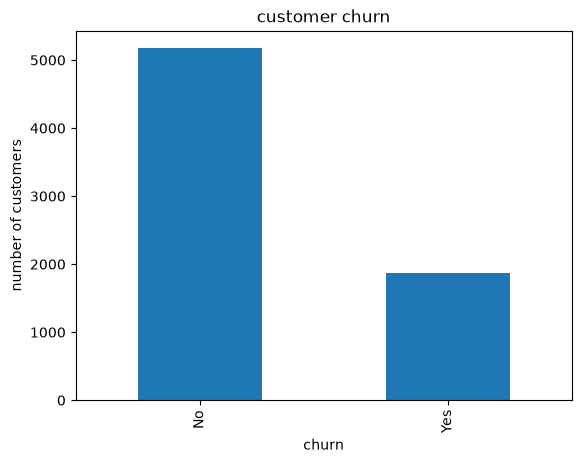

In [31]:
df['Churn'].value_counts().plot(kind="bar")
plt.title('customer churn')
plt.xlabel('churn')
plt.ylabel('number of customers')

plt.show()

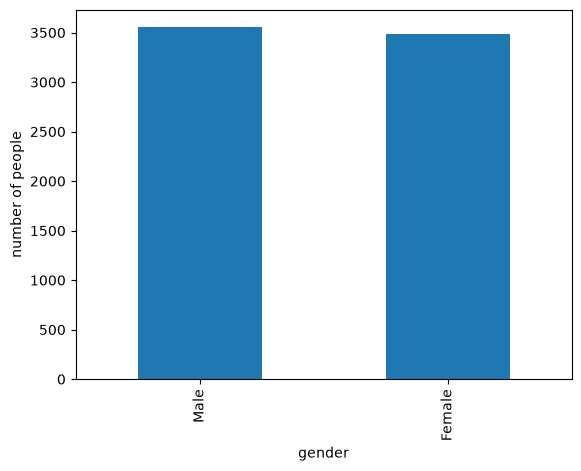

In [32]:
df['gender'].value_counts().plot(kind='bar')
plt.ylabel('number of people')

plt.show()

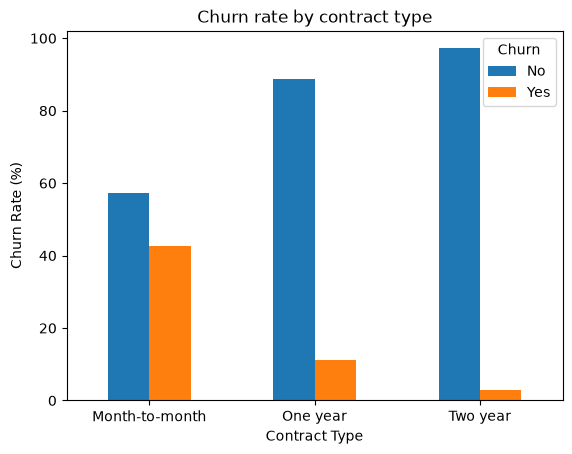

In [33]:
contract_churn = pd.crosstab(df['Contract'], df['Churn'], normalize='index') * 100
contract_churn.plot(kind='bar')

plt.title('Churn rate by contract type')
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=0)

plt.show()

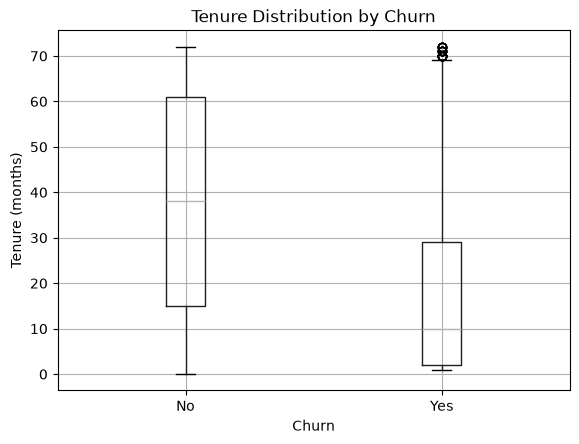

In [34]:
df.groupby('Churn')['tenure'].mean()

df.boxplot(column="tenure", by="Churn")

plt.title("Tenure Distribution by Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Tenure (months)")

plt.show()

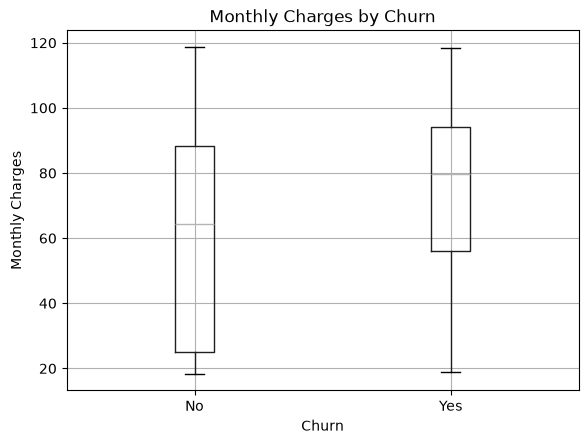

In [35]:
df.groupby('Churn')['MonthlyCharges'].mean()
df.boxplot(column='MonthlyCharges', by='Churn')
plt.title("Monthly Charges by Churn")
plt.suptitle("")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

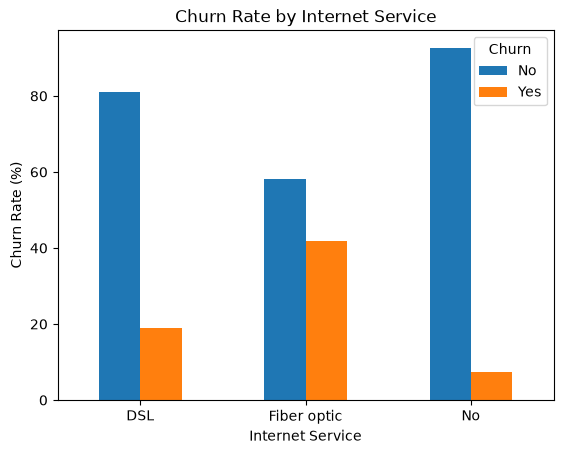

In [36]:
internet_churn = pd.crosstab(df['InternetService'],df['Churn'],normalize='index') * 100
internet_churn.plot(kind='bar')

plt.title("Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=0)

plt.show()